# Decoder stability across seeds -- CosMx pancreas (melton25)

The CosMx counterpart of [`notebooks/legnini_23/4_a_decoder_stability.ipynb`](../legnini_23/4_a_decoder_stability.ipynb),
running the *same* code: every function both notebooks use now lives in
[`src/decoder_stability.py`](../../src/decoder_stability.py), because the point of having two of
these is a like-for-like comparison and that only holds if the gene-selection code is shared
rather than copied.

**Two seed sweeps, five seeds each**, differing only in masking granularity:

| arm | registry task | `mask_strategy` | rate | sweep | checkpoints |
|---|---|---|---|---|---|
| `cell` | `melton25/node_reg` | `node` | 0.10 of the cells | [`f0ob49zb`](https://wandb.ai/francesca-drummer/InterScale_hyperparameter_sweep/sweeps/f0ob49zb) | `melton25_revision/seed_stability_cell/` |
| `gene` | `melton25/node_reg_genemask` | `gene` | 0.25 of each cell's genes | [`4ztsppu8`](https://wandb.ai/francesca-drummer/InterScale_hyperparameter_sweep/sweeps/4ztsppu8) | `melton25_revision/seed_stability_gene/` |

Flip the `MASKING` switch below and re-run from there; nothing after it is arm-specific.

**These are new sweeps, not `best_recon/`.** `results/melton25_revision/best_recon/` already holds
five seed models -- but they were trained by
`scripts/melton_jimenez_25/celltype_reconstruction_mse.py` as a plain per-seed retrain, not as a
wandb sweep, and only under cell masking. The two sweeps here are registered runs with a
gene-masking counterpart, which is what the masking-granularity comparison needs. They do
inherit `best_recon`'s configuration: **n_embed=128 with GaussianNLL**, sweep `sio2fsjm`'s winning
trial, *not* the registry defaults of n_embed=16 / SmoothL1. That is not optional --
`CombinedModel.load` uses `strict=False`, so loading these checkpoints against the registry
defaults returns a silently mis-shaped model instead of raising. `MELTON25_BEST` below reapplies
it.

**This notebook is heavy**: 386727 cells x 979 genes, and `get_model_output` materialises a
386727 x 1600 attention matrix (~2.5 GB) per seed (dropped immediately). Run it on a GPU node
inside the interscale container (`run_jupyter_interscale_cu128.sbatch`), not on a login node.

In [1]:
import scanpy as sc
import squidpy as sq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import issparse
import interscale

from pathlib import Path
from functools import partial

import warnings
warnings.filterwarnings('ignore')

In [2]:
import os

# LRZ home
if os.path.exists("/dss/dsshome1/05/di93tig"):
    print('LRZ cluster')
    CLUSTER = 'LRZ'
    BASE_DIR_REPO = "/dss/dsshome1/05/di93tig/1_projects/InterScale_reproducibility/"
    BASE_DIR_PROJECT = "/dss/dssfs03/tumdss/pn36po/pn36po-dss-0002/di93tig/Projects/A3_InterScale"
elif os.path.exists("/home/icb/francesca.drummer/"):
    print('HPC cluster')
    CLUSTER = 'HPC'
    BASE_DIR_REPO = "/home/icb/francesca.drummer/1-Projects/A3_InterScale/InterScale_reproducibility/"
    BASE_DIR_PROJECT = "/lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/"
else:
    print('unkown')
    CLUSTER = 'unknown'

DATA = "melton25"

HPC cluster


In [3]:
import yaml
with open(os.path.join(BASE_DIR_REPO, "figures/config.yml"), "r") as f:
    config = yaml.safe_load(f)

PALETTE = config["palettes"]["continuous"]

## Load data

In [4]:
COSMX = f'{BASE_DIR_PROJECT}/data/{DATA}.h5ad'
adata = sc.read_h5ad(COSMX)
adata

AnnData object with n_obs × n_vars = 386727 × 979
    obs: 'fov', 'Area', 'AspectRatio', 'CenterX_global_px', 'CenterY_global_px', 'Width', 'Height', 'Mean.MembraneStain', 'Max.MembraneStain', 'Mean.PanCK', 'Max.PanCK', 'Mean.GCG', 'Max.GCG', 'Mean.CD3', 'Max.CD3', 'Mean.DAPI', 'Max.DAPI', 'cell_ID', 'condition', 'slide', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_NegPrb', 'log1p_total_counts_NegPrb', 'pct_counts_NegPrb', 'n_genes', 'cell_type_coarse', 'CellTypes_max', 'slide_fov', 'slide_condition', 'split', 'split_0', 'split_1', 'split_2', 'globalX', 'globalY', 'sliding_window_square', 'sliding_window_h', 'sliding_window_v'
    obsm: 'X_pca', 'X_umap', 'spatial', 'spatial_fov'
    layers: 'counts', None (.X)

In [15]:
# melton25 keeps the expression the decoders reconstruct in .X (cfg.dataset.layer_key is None);
# layers holds raw counts only. That is the opposite of legnini23, where .X is counts and the
# target is layers['log1p_norm'] -- so nothing here may assume a layer name. `target_layer`
# below exposes .X under an explicit key instead, because gene_loadings/get_genes_dim both take
# a layer NAME and raise on None.
print('layers      :', list(adata.layers))
print('X   max     :', adata.X.max())
print('counts max  :', adata.layers['counts'].max())
print('zero-count cells:', int((adata.X.sum(1) == 0).sum()))
print('genes       :', adata.n_vars)
print()
print(adata.obs['cell_type_coarse'].value_counts())
print()
print(adata.obs['split'].value_counts())

layers      : ['counts', None, '_target', '40_y_pred_local', '40_y_pred_global', '41_y_pred_local', '41_y_pred_global', '42_y_pred_local', '42_y_pred_global', '43_y_pred_local', '43_y_pred_global', '44_y_pred_local', '44_y_pred_global']
X   max     : 4.8127866
counts max  : 325
zero-count cells: 0
genes       : 979

cell_type_coarse
Acinar         184395
Ductal         127936
Fibroblasts     25194
Immune          14578
Alpha           10318
Beta             9028
Endothelial      8528
Endocrine        3658
Mast             3092
Name: count, dtype: int64

split
test     151595
val      126421
train    108711
Name: count, dtype: int64


In [6]:
# The graphs the models were trained on: one per sliding_window_square, scoped per slide_fov.
sizes = adata.obs['sliding_window_square'].value_counts()
sizes = sizes[sizes > 0]
print(f"{len(sizes)} windows | largest {sizes.max()} | median {int(sizes.median())} cells")
sizes.head()

596 windows | largest 1600 | median 631 cells


sliding_window_square
3_25_window_4    1600
2_21_window_4    1498
3_6_window_4     1452
2_22_window_7    1440
3_11_window_8    1421
Name: count, dtype: int64

## Load trained models

In [7]:
import sys

project_root = Path(BASE_DIR_REPO)  # InterScale_reproducibility, for `from src.* import ...`
sys.path.insert(0, str(project_root))

# The interscale package is a SIBLING of InterScale_reproducibility, not a subdirectory of it.
INTERSCALE_REPO = project_root.parent / "interscale"
REGISTRY = INTERSCALE_REPO / "config_files" / "registry.yaml"

DATASET = "melton25"

# ---------------------------------------------------------------------------------------------
# WHICH MASKING ARM TO LOAD.  Flip this and re-run from here; nothing below is arm-specific.
#
#   "cell"  whole cells are blanked and all G genes of them are scored  (mask_strategy "node")
#   "gene"  individual (cell, gene) entries are blanked and only those are scored
#
# The two sweeps are matched: same five seeds, same schedule, same architecture (sweep
# sio2fsjm's winning trial), both trained with MASK_VALUE = -1. They differ only in masking
# granularity and its rate, so a difference in how stable the gene loadings are across seeds is
# attributable to that.
#
# The rate is not the same NUMBER in the two arms because it is not the same QUANTITY: 0.10 of
# the CELLS against 0.25 of every cell's GENES. 0.10 is best_recon's own value; 0.25 is carried
# over from legnini23, where it was measured -- it has NOT been swept on this dataset, whose
# 979-gene panel offers an order of magnitude more within-cell redundancy for gene masking to
# exploit than legnini23's 88. If the gene arm loses here, sweep the rate before concluding
# anything about granularity.
# ---------------------------------------------------------------------------------------------
# Reading the env var lets the same notebook be executed headlessly once per arm
# (scripts/melton_jimenez_25/run_decoder_stability.sh); interactively it is just "cell".
MASKING = os.environ.get("MASKING", "cell")  # "cell" | "gene"

ARMS = {
    "cell": {
        "task": "node_reg",
        "sweep_id": "f0ob49zb",  # config_files/sweeps/seed_cell_masking_melton25.yaml
        "models_subdir": "seed_stability_cell",
        # The registry default for this pair is 0.3; the sweep pinned 0.1. It changes no tensor
        # shape, so load() would succeed either way -- which is exactly why omitting it would go
        # unnoticed and the config recorded here would not be the one that trained.
        "overrides": {"dataset.mask_percentage": 0.1},
    },
    "gene": {
        "task": "node_reg_genemask",
        "sweep_id": "4ztsppu8",  # config_files/sweeps/seed_gene_masking_melton25.yaml
        "models_subdir": "seed_stability_gene",
        # Likewise below the task file's 0.5.
        "overrides": {"dataset.mask_percentage": 0.25},
    },
}
assert MASKING in ARMS, f"MASKING must be one of {sorted(ARMS)}"
ARM = ARMS[MASKING]
TASK, SWEEP_ID = ARM["task"], ARM["sweep_id"]

MODELS_DIR = Path(BASE_DIR_PROJECT) / "results" / "melton25_revision" / ARM["models_subdir"]
# Per-arm, so the two arms' per-gene CSVs sit side by side instead of overwriting each other.
RESULTS_DIR = Path(BASE_DIR_PROJECT) / "results" / DATA / f"rec_seed_stablity_{MASKING}"

assert REGISTRY.exists(), f"registry not found: {REGISTRY}"
assert MODELS_DIR.exists(), (
    f"checkpoint dir not found: {MODELS_DIR}\n"
    f"Train it with:  SWEEP_ID={SWEEP_ID} sbatch scripts/run.sh {DATASET} {TASK} "
    f"--sweep_cfg config_files/sweeps/seed_{MASKING}_masking_melton25.yaml "
    f"--sweep_goal robustness --metric val_concordance_corr --count 5"
)
print(f"masking     {MASKING} (task {TASK}, sweep {SWEEP_ID})")
print(f"registry    {REGISTRY}\ncheckpoints {MODELS_DIR}\nresults     {RESULTS_DIR}")

masking     cell (task node_reg, sweep f0ob49zb)
registry    /home/icb/francesca.drummer/1-Projects/A3_InterScale/interscale/config_files/registry.yaml
checkpoints /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/results/melton25_revision/seed_stability_cell
results     /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/results/melton25/rec_seed_stablity_cell


In [8]:
import wandb

from interscale.tl.utils import get_model_filename_prefix, set_full_reproducibility
from interscale.tl import remove_zero_expression_cells
from src.wandb import Wandb_evaluation

# Shared with notebooks/legnini_23/4_decoder_stability.ipynb -- same selection code, both
# datasets. See src/decoder_stability.py.
from src.decoder_stability import (
    GROUP_COLORS,
    build_cfg as _build_cfg,
    collect_gene_sets,
    expected_intersection,
    intersection_by_k,
    intersection_tail_probability,
    local_global_split,
    overlap_matrix,
    per_gene_metrics,
    plot_intersection_by_k,
    plot_membership,
    plot_tail_prob_by_k,
    run_seed_inference,
    tail_prob_by_k,
    target_layer,
)

wandb.login()

wandb: ERROR Failed to detect the name of this notebook. You can set it manually with the WANDB_NOTEBOOK_NAME environment variable to enable code saving.
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/icb/francesca.drummer/.netrc.
wandb: Currently logged in as: francesca-drummer to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

## Load WandB sweep

Five seeds, every other model parameter identical. `Wandb_evaluation` hardcodes
entity/project to `francesca-drummer/InterScale_hyperparameter_sweep`, which is where
`main_sweep.py` registers sweeps by default -- so `SWEEP_ID` alone identifies the arm.

In [9]:
# NOT `wandb = ...`: that name is the wandb module, imported above, and rebinding it is what
# makes `wandb.Api(timeout=60)` raise AttributeError further down. The first argument is only a
# label.
sweep_eval = Wandb_evaluation(
    "InterScale",
    SWEEP_ID,
    local_component=True,
    global_component=True,
    sweep_goal="robustness",
    classes=[None],
)

In [10]:
sweep_df = sweep_eval.get_dataframe()
sweep_df

,id,name,seed,state,mask_percentage,mask_strategy,pct_mask_nodes,radius,decoder_type,runtime_seconds,total_parameters,test_r2,test_pearson_corr
0,hi5bhqep,dual_melton25_regr_node_40_GCN_self-attn-trans...,40,finished,0.1,node,0.1,None,None,217,769318,-4.238268,0.018627
1,e5dvlhwj,dual_melton25_regr_node_41_GCN_self-attn-trans...,41,finished,0.1,node,0.1,None,None,372,769318,-4.484244,0.022026
2,3ub3be2u,dual_melton25_regr_node_42_GCN_self-attn-trans...,42,finished,0.1,node,0.1,None,None,341,769318,-4.370060,0.023535
3,cp4iyf0e,dual_melton25_regr_node_43_GCN_self-attn-trans...,43,finished,0.1,node,0.1,None,None,220,769318,-4.495187,0.020180
4,od23jumx,dual_melton25_regr_node_44_GCN_self-attn-trans...,44,finished,0.1,node,0.1,None,None,307,769318,-4.346736,0.020048


## Model inference

Load each of the five seed models, run inference, and keep

- `local_emb[seed]` / `global_emb[seed]` &mdash; the two embeddings, `(n_cells, n_embed)`
- `models[seed]` &mdash; the loaded `CombinedModel`, for the gene-loading section below
- `performance[seed]` &mdash; per-gene reconstruction scores, also written to
  `results/melton25/rec_seed_stablity_{MASKING}/model_{seed}_performance.csv`

The models are loaded from disk rather than from wandb artifacts: both sweeps pinned
`model.save`, so all ten checkpoints already sit on lustre.

**The seed cannot be read off `run.config['optim']['seed']`.** `main_sweep.py` calls
`wandb.init(config=cfg)` *before* `apply_sweep_config`, so the nested config wandb stored is the
base config &mdash; seed 44 for all five runs, which is also why every run is named
`..._44_...`. Only the flattened `run.config['optim.seed']` (what `sweep_df["seed"]` reads)
carries the trial's actual value, and it is what `build_cfg` applies below.

In [11]:
# Sweep sio2fsjm's winning trial (run ycjcovv2) -- i.e. what these checkpoints were actually
# trained with, and what `results/melton25_revision/best_recon/` holds. It has to be reapplied
# on top of the resolved registry pair: the registry alone gives n_embed=16 / SmoothL1, which
# builds a differently shaped module, and CombinedModel.load uses strict=False -- so the
# mismatch comes back as a silently wrong model, not an error.
#
# Keep in sync with scripts/melton_jimenez_25/celltype_reconstruction_mse.py::BEST,
# config_files/sweeps/seed_{cell,gene}_masking_melton25.yaml and
# config_files/sweeps/component_ablation_melton25.yaml.
#
# `dataset.pct_mask_nodes` is deliberately absent: that key no longer exists (it was split into
# dataset.mask_strategy + dataset.mask_percentage), and apply_sweep_config does not allow new
# keys, so passing it raises. The rate lives in ARM["overrides"] instead, because it is the one
# hyperparameter the two arms do not share.
#
# optim.n_epochs is also absent, so both arms inherit the registry default (100) that
# best_recon/ was trained under. Unlike legnini23 -- where nothing ever early-stops and 100
# undertrains badly -- EarlyStopping does fire on this dataset, around epoch 40 (min_epochs 40,
# patience 5), so the cap is not what ends these runs. Check `stopped_epoch` per trial anyway:
# early stopping has been observed to truncate arms unequally, which would confound the
# comparison.
MELTON25_BEST = {
    "optim.loss": "GaussianNLL",
    "model.n_embed": 128,
    "model.local_component.parameters.hidden_dim": 256,
    "model.local_component.parameters.num_layers": 1,
    "model.local_component.parameters.dropout_local": 0.0,
    "model.global_component.parameters.num_layers": 2,
    "model.global_component.parameters.n_heads": 2,
    "model.global_component.parameters.dim_feedforward": 256,
    "model.global_component.parameters.dropout_global": 0.0,
    "dataset.batch_size": 8,
    "optim.lr": 0.005,
    "optim.wd": 0.01,
    "optim.lr_warmup": 20,
    "optim.monitor": "val_concordance_corr",
}

# optim.seed is not cosmetic: get_model_filename_prefix puts it in the checkpoint name, which is
# what makes the five models separable when load() picks the file. The same prefix carries
# dataset.name, which the registry sets to melton25_genemask for the gene arm -- so the two
# arms' checkpoints are distinguishable even before the directory split.
build_cfg = partial(
    _build_cfg,
    DATASET,
    TASK,
    REGISTRY,
    models_dir=MODELS_DIR,
    sweep_overrides=MELTON25_BEST,
    overrides=ARM["overrides"],
)

In [12]:
# Training filtered zero-expression cells; inference has to filter identically or the per-window
# graphs handed to the model are not the graphs it was trained on. Unlike legnini23 there is no
# later cell that repoints .X, so the helper can read .X directly.
adata = remove_zero_expression_cells(adata)

SEEDS = sorted(sweep_df["seed"].astype(int))
print("seeds:", SEEDS)
assert len(SEEDS) == 5, (
    f"{len(SEEDS)} finished runs in sweep {SWEEP_ID}, expected 5 -- the agent is still running "
    f"or a trial failed. Resume with the same SWEEP_ID; a grid sweep does not repeat trials."
)

cfg0 = build_cfg(SEEDS[0])
layer_key = target_layer(adata, cfg0)
window_key = cfg0.dataset.sample_key[0]
assert cfg0.model.decoder.dual_decoder, (
    "cfg has no local decoder, so there is nothing to compare against the global one"
)

# Every checkpoint must be on disk before the loop starts -- load() with a missing file is a
# slower and less obvious failure than this.
missing = [
    s for s in SEEDS
    if not (MODELS_DIR / f"{get_model_filename_prefix(build_cfg(s), True, True)}model.pt").exists()
]
assert not missing, f"no checkpoint for seeds {missing} in {MODELS_DIR}"

# Below max_seq_len, tl/padding.py random-subsamples each graph every call instead of erroring,
# so the predictions would come from a graph the model never saw.
sizes = adata.obs[window_key].value_counts()
sizes = sizes[sizes > 0]
assert sizes.max() <= cfg0.model.global_component.parameters.max_seq_len, (
    f"largest {window_key} window is {sizes.max()} cells but max_seq_len is "
    f"{cfg0.model.global_component.parameters.max_seq_len}"
)
print(f"{len(sizes)} graphs over '{window_key}', largest {sizes.max()} cells "
      f"(max_seq_len {cfg0.model.global_component.parameters.max_seq_len})")
print(f"n_embed {cfg0.model.n_embed} | loss {cfg0.optim.loss} | "
      f"mask {cfg0.dataset.mask_strategy} @ {cfg0.dataset.mask_percentage} | "
      f"target layer '{layer_key}'")

# Ground truth is what the decoders were trained to reconstruct.
_t = adata.layers[layer_key]
y_true = np.asarray(_t.todense() if issparse(_t) else _t, dtype=np.float64)
print(f"y_true {y_true.shape} ({y_true.nbytes / 1e9:.1f} GB)")

Nr. of zero expression cells: 0
seeds: [40, 41, 42, 43, 44]
applied sweep parameters: ['dataset.batch_size', 'model.global_component.parameters.dim_feedforward', 'model.global_component.parameters.dropout_global', 'model.global_component.parameters.n_heads', 'model.global_component.parameters.num_layers', 'model.local_component.parameters.dropout_local', 'model.local_component.parameters.hidden_dim', 'model.local_component.parameters.num_layers', 'model.n_embed', 'optim.loss', 'optim.lr', 'optim.lr_warmup', 'optim.monitor', 'optim.wd']
applied sweep parameters: ['dataset.batch_size', 'model.global_component.parameters.dim_feedforward', 'model.global_component.parameters.dropout_global', 'model.global_component.parameters.n_heads', 'model.global_component.parameters.num_layers', 'model.local_component.parameters.dropout_local', 'model.local_component.parameters.hidden_dim', 'model.local_component.parameters.num_layers', 'model.n_embed', 'optim.loss', 'optim.lr', 'optim.lr_warmup', 'opti

In [13]:
# Writes obsm[f"{seed}_local_emb"] / obsm[f"{seed}_global_emb"] and
# layers[f"{seed}_y_pred_local"] / layers[f"{seed}_y_pred_global"] into adata, plus one per-gene
# csv per seed under RESULTS_DIR. The seed prefix is what lets the gene-loading section below
# revisit any seed, not only the last one inferred.
adata, models, local_emb, global_emb, performance = run_seed_inference(
    adata,
    SEEDS,
    build_cfg,
    MODELS_DIR,
    RESULTS_DIR,
    y_true=y_true,
    repro_seed=40,
)

applied sweep parameters: ['dataset.batch_size', 'model.global_component.parameters.dim_feedforward', 'model.global_component.parameters.dropout_global', 'model.global_component.parameters.n_heads', 'model.global_component.parameters.num_layers', 'model.local_component.parameters.dropout_local', 'model.local_component.parameters.hidden_dim', 'model.local_component.parameters.num_layers', 'model.n_embed', 'optim.loss', 'optim.lr', 'optim.lr_warmup', 'optim.monitor', 'optim.wd']
Loading model from /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/results/melton25_revision/seed_stability_cell/dual_melton25_regr_node_40_GCN_self-attn-transformer_model.pt
Unclear checkpoint format. Attempting remapping anyway.
State dict remapping applied. Source detected: unknown
Load GEX from .X
INFO     Creating graph using `None` transform and `1` libraries.                                                  
INFO     Creating graph using `None` transform and `1` libraries.        

In [14]:
# Test-split medians per seed, both decoders. Medians, not means: a handful of low-variance
# genes drive mean R2 to -1e2 and make it useless as a summary.
summary = pd.concat(
    {s: performance[s].query("split == 'test'")
                      .groupby("decoder")[["r2", "r2_offset_corrected", "pearson", "cosine_sim", "mse"]]
                      .median()
     for s in SEEDS},
    names=["seed"],
)
print(summary.to_string())
print()
print("across-seed spread (SD of the per-seed medians):")
print(summary.groupby("decoder").std(ddof=1).to_string())

                    r2  r2_offset_corrected   pearson  cosine_sim       mse
seed decoder                                                               
40   global  -0.517616            -0.231539  0.009044    0.129672  0.053505
     local   -5.264157            -2.992491  0.007465    0.041585  0.203738
41   global  -0.746740            -0.363257  0.010945    0.119102  0.062481
     local   -4.959423            -2.581223  0.007678    0.044847  0.195009
42   global  -0.513050            -0.203008  0.012151    0.138561  0.057762
     local   -5.186680            -2.231592  0.009643    0.078883  0.213060
43   global  -0.449400            -0.202511  0.012909    0.135505  0.052792
     local   -5.141417            -2.895628  0.007893    0.031454  0.213553
44   global  -0.425035            -0.147027  0.014172    0.149487  0.050914
     local   -4.499091            -1.811165  0.007840    0.045527  0.200876

across-seed spread (SD of the per-seed medians):
               r2  r2_offset_corrected

## Gene loadings

`collect_gene_sets` runs `gene_loadings` -> `calculate_dim_importance` -> `get_genes_dim` per
seed, over all 128 dimensions, ranked by `loading_x_sd`.

Note it standardizes the **local** loadings by the **local** embedding's std.
`DualDecoderCombinedModule.predict_local` decodes the local embedding through the local decoder,
so using the global embedding's std there rescales every local dimension by the wrong constant,
which changes the dimension ranking and therefore which genes are selected. The legnini notebook
used to pass the global key on both sides; that is fixed in the shared helper, so neither
notebook's local sets reproduce the pre-refactor run.

In [20]:
# The genes the publication figure reports for this dataset: panel F, left = local embeddings,
# right = global embeddings. All 49 are in the 979-gene CosMx panel, so a gene missing from a
# seed's set was not recovered rather than not available.
#
# The four bolded in the figure -- GLUL, INS, REG1A (local) and IL32, IGF1R, C1QC (global) --
# are the ones the paper calls out; they are not treated specially here, but they are the rows
# to look at first in the membership plots.
TRUE_LOCAL_GENES = [
    'BTG1', 'CD44', 'ETV5', 'GLUL', 'H2AZ1', 'MT1X', 'CYSTM1', 'LDLR', 'HLA-A', 'TPM2', 'APP',
    'SPRY2', 'TUBB', 'DST', 'CUZD1', 'PTGES3', 'RARRES2', 'SRC', 'INS', 'CXCL2', 'REG1A',
    'H4C3', 'GDF15', 'NEAT1', 'GPX1',
]
TRUE_GLOBAL_GENES = [
    'CDKN1A', 'FABP5', 'MIF', 'HSP90AB1', 'TNFRSF12A', 'IL12RB1', 'SPP1', 'RPL22', 'PDGFD',
    'GPX3', 'MEG3', 'BTG1', 'IL32', 'IGFBP7', 'HLA-A', 'CALM3', 'TPM1', 'IGF1R', 'HLA-E',
    'GDF15', 'TAGLN', 'IL10RB', 'NDRG1', 'C1QC',
]

# The pool a selection could have drawn from. NOT the whole 979-gene panel: min_frac=0.1 below
# removes every gene expressed in under 10% of cells before any ranking happens, so those genes
# were never candidates and counting them inflates the pool -- which deflates the chance-overlap
# baselines that every stability claim here is read against.
#
# enforce_specificity=True narrows the effective pool further, per dimension, in a way that has
# no single number. So POOL is an UPPER bound on the candidate set, and the plotted random
# expectation is correspondingly a LOWER bound on chance overlap. Read the observed overlap as
# beating chance only when it clears the baseline comfortably.
# Defined here rather than next to the other selection settings because the pool has to be
# computed before it; collect_gene_sets below is passed this same value, and the two MUST agree
# or the baselines describe a different candidate set than the one that was selected from.
MIN_FRAC = 0.1

_X = adata.layers[layer_key]
_frac = np.asarray((_X > 0).mean(axis=0)).ravel()
POOL = int((_frac >= MIN_FRAC).sum())
print(f"panel {adata.n_vars} genes -> {POOL} pass min_frac={MIN_FRAC} "
      f"({POOL / adata.n_vars:.0%} of the panel)")

panel = set(adata.var_names)
for name, genes in [("local", TRUE_LOCAL_GENES), ("global", TRUE_GLOBAL_GENES)]:
    absent = [g for g in genes if g not in panel]
    assert not absent, f"{name} publication genes not in the panel: {absent}"
    print(f"{name:6s}: {len(genes)} published genes, all in the {POOL}-gene panel")
print("shared between the two published lists:",
      sorted(set(TRUE_LOCAL_GENES) & set(TRUE_GLOBAL_GENES)))

panel 979 genes -> 217 pass min_frac=0.1 (22% of the panel)
local : 25 published genes, all in the 217-gene panel
global: 24 published genes, all in the 217-gene panel
shared between the two published lists: ['BTG1', 'GDF15', 'HLA-A']



60% cumulative variance reached with 59 dimensions:
Embedding dimensions (sorted by importance):
[108, 97, 8, 94, 85, 44, 91, 56, 37, 113, 3, 13, 16, 111, 103, 6, 27, 117, 119, 20, 51, 60, 14, 17, 25, 69, 105, 67, 15, 102, 34, 120, 57, 93, 86, 115, 79, 26, 40, 36, 90, 122, 32, 66, 33, 87, 92, 75, 38, 74, 7, 54, 109, 71, 114, 68, 121, 21, 101]

60% cumulative variance reached with 49 dimensions:
Embedding dimensions (sorted by importance):
[108, 112, 91, 16, 97, 84, 52, 85, 94, 69, 43, 119, 113, 11, 5, 55, 17, 33, 103, 34, 27, 9, 44, 2, 114, 86, 124, 107, 71, 48, 72, 79, 22, 15, 56, 117, 23, 92, 40, 46, 37, 122, 25, 93, 75, 31, 115, 101, 65]


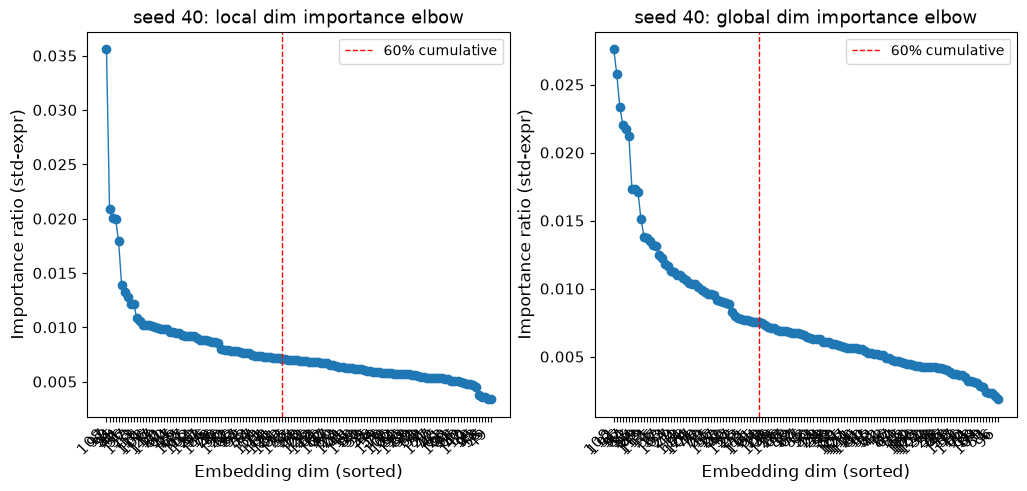

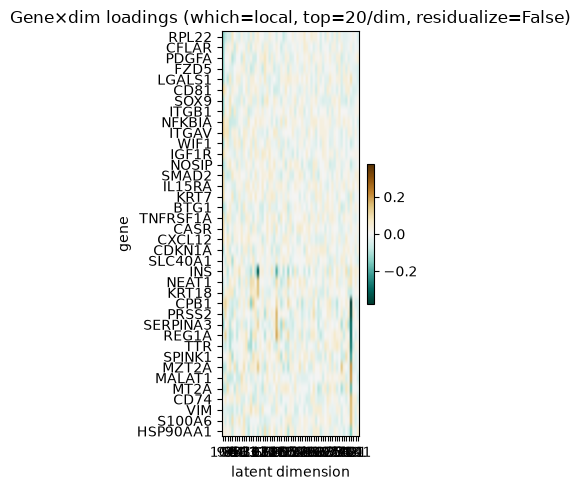

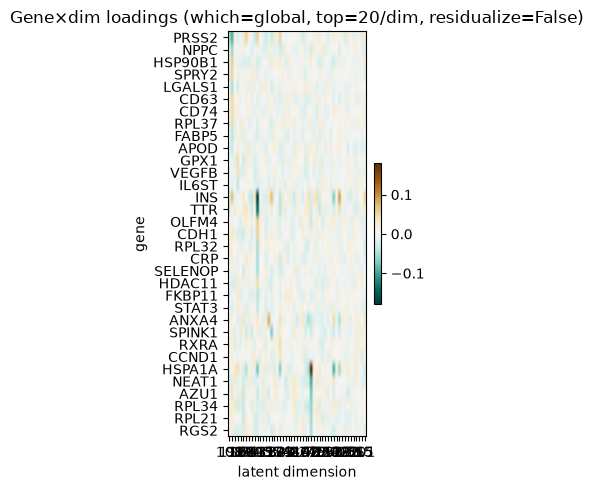

seed 40 local :  38 genes off 59 dims [np.int64(3), np.int64(6), np.int64(7), np.int64(8), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(20), np.int64(21), np.int64(25)] ...
seed 40 global:  33 genes off 49 dims [np.int64(2), np.int64(5), np.int64(9), np.int64(11), np.int64(15), np.int64(16), np.int64(17), np.int64(22), np.int64(23), np.int64(25), np.int64(27), np.int64(31)] ...

60% cumulative variance reached with 59 dimensions:
Embedding dimensions (sorted by importance):
[19, 76, 49, 111, 4, 23, 116, 87, 69, 45, 6, 75, 43, 82, 64, 11, 54, 61, 89, 81, 16, 98, 99, 59, 20, 22, 48, 94, 109, 47, 46, 122, 119, 114, 56, 120, 85, 83, 84, 101, 65, 5, 62, 1, 113, 100, 126, 91, 115, 33, 88, 50, 110, 18, 30, 70, 68, 74, 92]

60% cumulative variance reached with 48 dimensions:
Embedding dimensions (sorted by importance):
[59, 36, 111, 76, 20, 123, 23, 19, 87, 90, 4, 22, 77, 75, 50, 45, 61, 106, 91, 43, 66, 69, 107, 124, 6, 116, 68, 82, 65, 17, 84, 63, 67, 25, 49

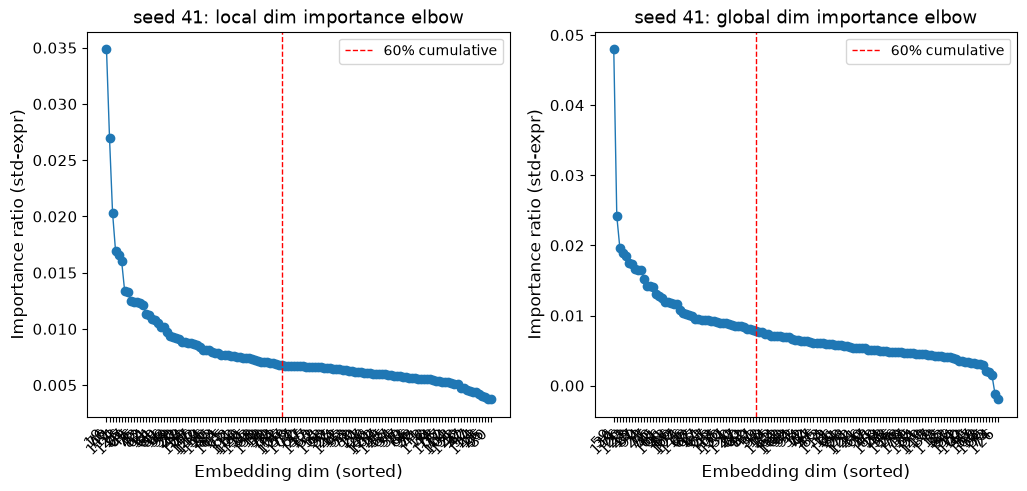

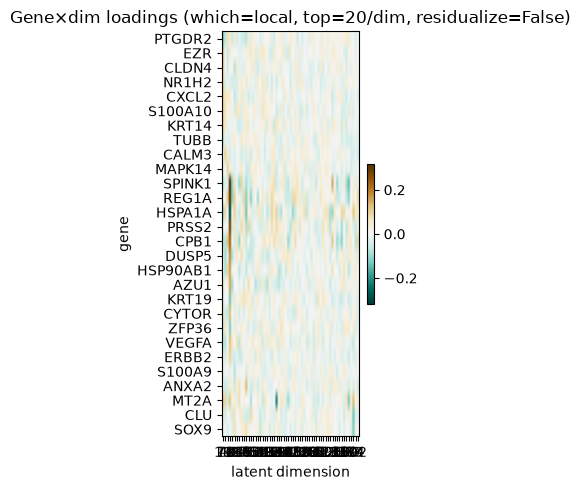

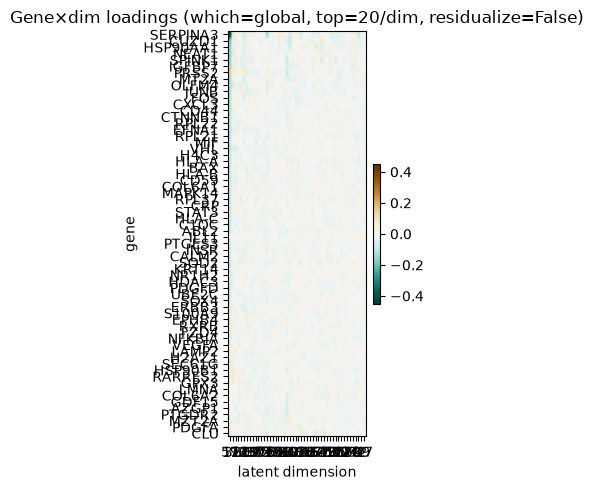

seed 41 local :  28 genes off 59 dims [np.int64(1), np.int64(4), np.int64(5), np.int64(6), np.int64(11), np.int64(16), np.int64(18), np.int64(19), np.int64(20), np.int64(22), np.int64(23), np.int64(30)] ...
seed 41 global:  64 genes off 48 dims [np.int64(0), np.int64(4), np.int64(6), np.int64(13), np.int64(17), np.int64(19), np.int64(20), np.int64(22), np.int64(23), np.int64(25), np.int64(27), np.int64(30)] ...

60% cumulative variance reached with 57 dimensions:
Embedding dimensions (sorted by importance):
[44, 48, 116, 10, 109, 68, 39, 80, 49, 67, 22, 85, 57, 75, 38, 15, 99, 14, 125, 55, 45, 83, 86, 77, 112, 82, 92, 63, 72, 43, 97, 53, 21, 19, 2, 111, 52, 54, 106, 66, 117, 29, 98, 46, 95, 20, 79, 4, 121, 96, 30, 12, 110, 103, 6, 34, 104]

60% cumulative variance reached with 46 dimensions:
Embedding dimensions (sorted by importance):
[44, 80, 56, 90, 69, 116, 48, 39, 47, 55, 117, 68, 28, 106, 78, 59, 70, 82, 93, 45, 123, 77, 58, 3, 103, 52, 66, 71, 125, 113, 33, 32, 1, 109, 94, 83, 4

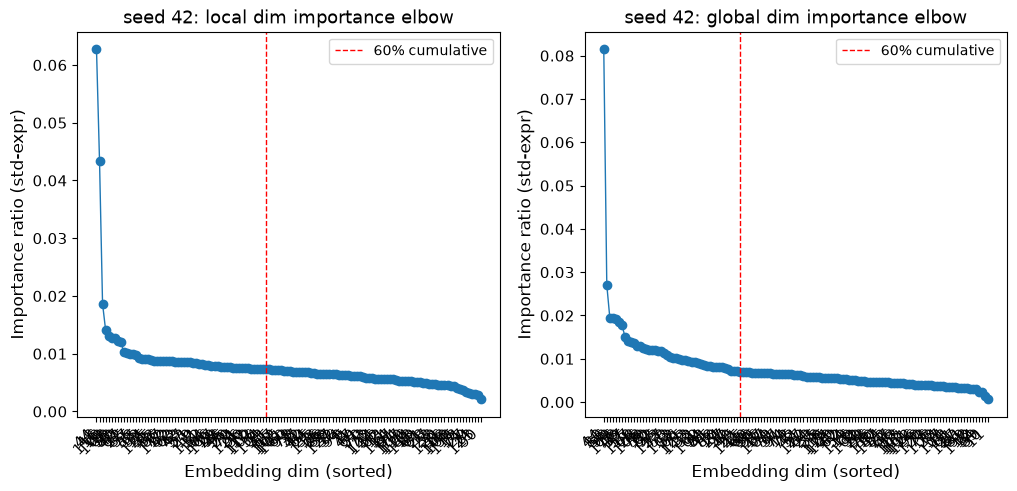

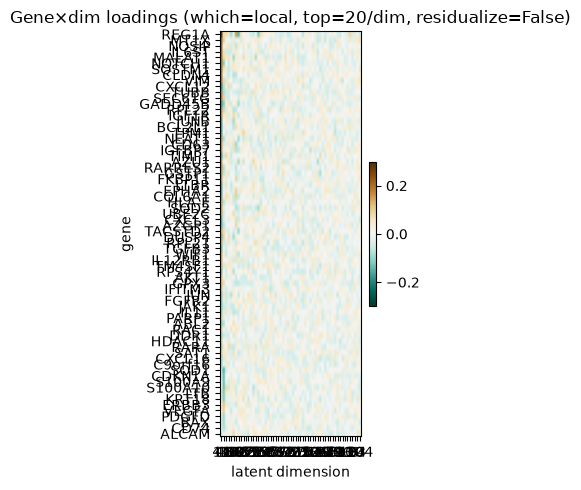

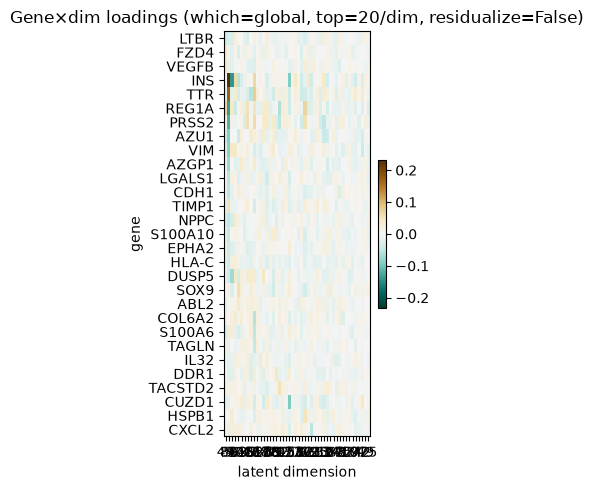

seed 42 local :  70 genes off 57 dims [np.int64(2), np.int64(4), np.int64(6), np.int64(10), np.int64(12), np.int64(14), np.int64(15), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(29)] ...
seed 42 global:  29 genes off 46 dims [np.int64(1), np.int64(3), np.int64(7), np.int64(10), np.int64(24), np.int64(25), np.int64(28), np.int64(32), np.int64(33), np.int64(39), np.int64(41), np.int64(42)] ...

60% cumulative variance reached with 57 dimensions:
Embedding dimensions (sorted by importance):
[16, 32, 63, 79, 26, 72, 119, 23, 29, 25, 107, 4, 48, 21, 101, 22, 19, 66, 71, 60, 12, 96, 73, 52, 118, 125, 6, 78, 39, 81, 88, 126, 84, 109, 93, 103, 13, 18, 37, 1, 17, 111, 94, 115, 5, 34, 33, 116, 112, 9, 54, 89, 46, 40, 20, 49, 42]

60% cumulative variance reached with 47 dimensions:
Embedding dimensions (sorted by importance):
[16, 32, 97, 5, 119, 38, 28, 46, 49, 87, 24, 23, 21, 14, 84, 113, 101, 62, 79, 53, 40, 66, 19, 91, 73, 85, 33, 107, 18, 13, 88, 44, 93, 55, 9, 41, 81, 1

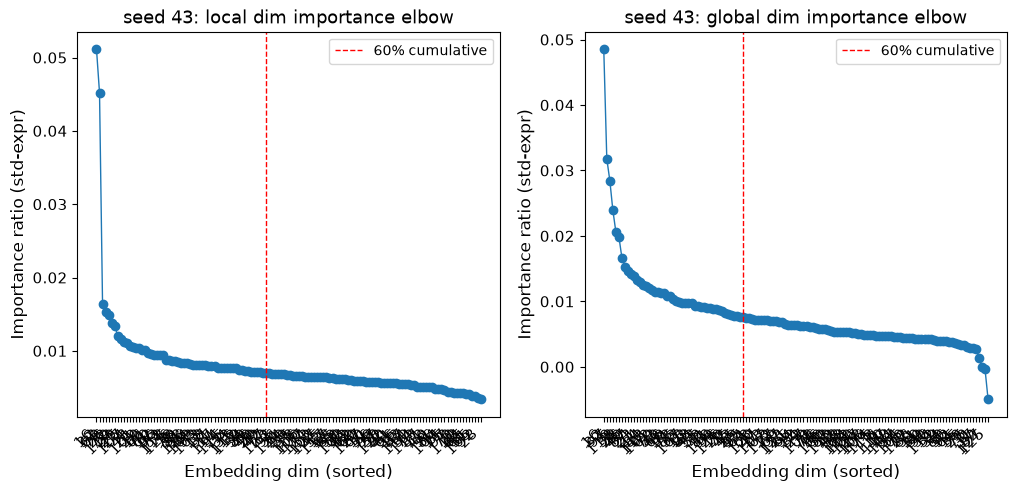

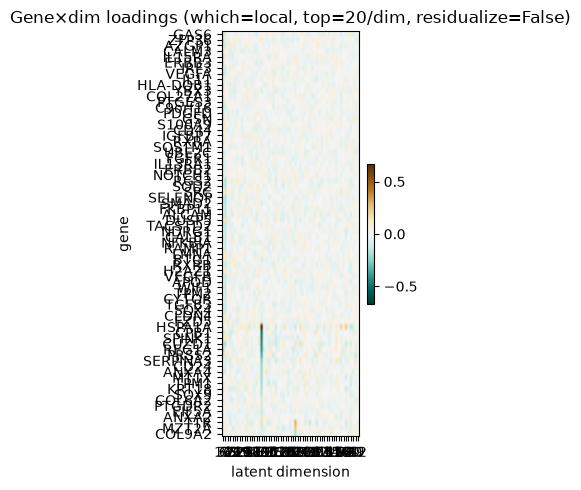

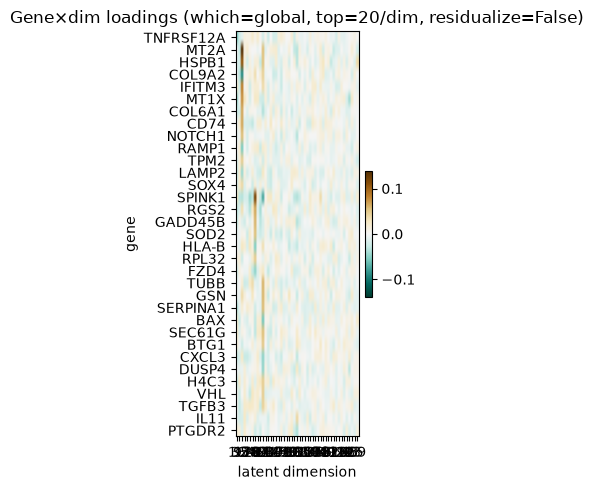

seed 43 local :  72 genes off 57 dims [np.int64(1), np.int64(4), np.int64(5), np.int64(6), np.int64(9), np.int64(12), np.int64(13), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20)] ...
seed 43 global:  33 genes off 47 dims [np.int64(2), np.int64(5), np.int64(9), np.int64(13), np.int64(14), np.int64(16), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(23), np.int64(24)] ...

60% cumulative variance reached with 57 dimensions:
Embedding dimensions (sorted by importance):
[50, 104, 22, 106, 123, 126, 119, 27, 120, 115, 127, 90, 88, 66, 107, 112, 59, 8, 122, 111, 12, 5, 124, 64, 19, 100, 118, 31, 79, 11, 47, 15, 58, 82, 40, 98, 20, 13, 80, 73, 103, 56, 17, 25, 10, 26, 93, 18, 3, 24, 72, 87, 36, 57, 116, 67, 54]

60% cumulative variance reached with 46 dimensions:
Embedding dimensions (sorted by importance):
[50, 33, 104, 115, 53, 74, 65, 79, 22, 100, 27, 37, 18, 116, 15, 30, 97, 55, 118, 81, 70, 43, 34, 48, 58, 123, 121, 66, 21, 114, 92, 119, 106, 95, 

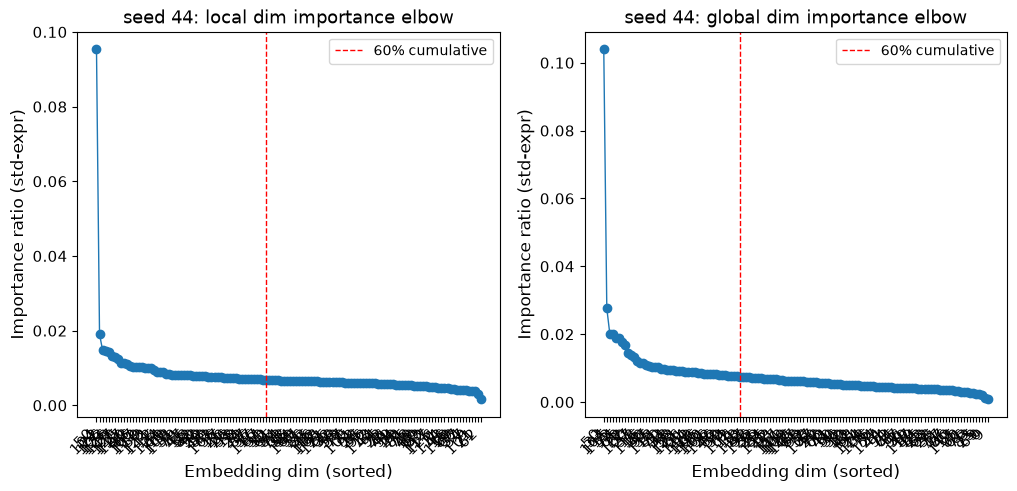

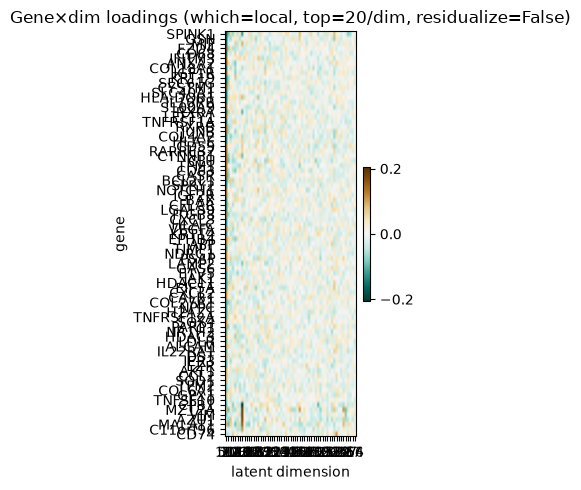

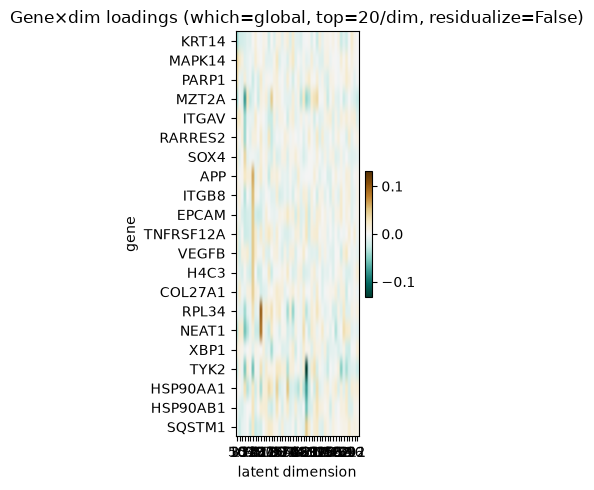

seed 44 local :  83 genes off 57 dims [np.int64(3), np.int64(5), np.int64(8), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(15), np.int64(17), np.int64(18), np.int64(19), np.int64(20)] ...
seed 44 global:  21 genes off 46 dims [np.int64(4), np.int64(11), np.int64(15), np.int64(16), np.int64(18), np.int64(21), np.int64(22), np.int64(27), np.int64(30), np.int64(33), np.int64(34), np.int64(37)] ...

program sizes  local [38, 28, 70, 72, 83]  global [33, 64, 29, 33, 21]  (pool 217)


In [32]:
# ---------------------------------------------------------------------------------------------
# THESE FIVE VALUES ARE FIG. 3F's, NOT GUESSES. They are copied from
# scripts/legnini_23/4a_seed_stability_extract.py, whose call site is commented "the same call
# Fig. 3F uses", and confirmed against best_recon/analysis/seed4*_meta.json, which records
# cumulative_cutoff=0.6 and n_top=20 for the published models.
#
# They differ from the legnini23 notebook's settings, and the differences matter:
#
#   cumulative_cutoff 0.6  keeps 41-50 of the 128 dimensions on this dataset -- NOT the 5-7 the
#                          figure's panel labels might suggest. Those labels (57, 87, 48, 103,
#                          70, 33, 3 local; 48, 70, 57, 3, 96 global) are the handful the panel
#                          DISPLAYS; they are a subset of the ~45 actually selected.
#   n_top 20               20 genes per dimension, not legnini23's 3.
#   min_frac 0.1           drops genes expressed in under 10% of cells. legnini23 uses 0.0.
#   enforce_specificity    True, not False. Together with min_frac this is what collapses
#                          ~45 dims x 20 genes into the ~29 local / ~43 global gene programs
#                          best_recon actually recorded -- i.e. the scale of the published
#                          25- and 24-gene lists. Without it the sets would be most of the panel
#                          and every overlap number below would be inflated.
# ---------------------------------------------------------------------------------------------
DIM_CUTOFF = 0.6
N_TOP = 20
ENFORCE_SPECIFICITY = True
SPECIFICITY_MIN = 1.5

df_local_list, df_global_list, dims_used = collect_gene_sets(
    adata,
    models,
    SEEDS,
    layer_key=layer_key,
    dims=None,                  # use the cutoff's selection, not all 128 dims
    cumulative_cutoff=DIM_CUTOFF,
    n_top=N_TOP,
    min_frac=MIN_FRAC,          # set with POOL above; the two must agree
    rank_by="loading_x_sd",
    enforce_specificity=ENFORCE_SPECIFICITY,
    specificity_min=SPECIFICITY_MIN,
    spacing=2,
    allow_empty=True,
    plot=True,
)

# Computed from the results rather than from an exception, so it is per seed, not per arm.
n_local = [len(d) for d in df_local_list]
n_global = [len(d) for d in df_global_list]
HAS_PROGRAMS = any(n_local) or any(n_global)
print(f"\nprogram sizes  local {n_local}  global {n_global}  (pool {POOL})")
if not HAS_PROGRAMS:
    print("NO seed produced a program in either component -- every number below is 0 by that "
          "fact, not by instability.")
elif not (all(n_local) and all(n_global)):
    print("Some seeds produced no program; the overlap statistics below average over seeds that "
          "did and seeds that could not, so read the per-seed sizes above first.")


In [33]:
# The figure's panel labels, and best_recon's own recorded selection, as two reference points.
#
# Dimension INDICES are not expected to reproduce across seeds -- best_recon's five seeds share
# almost none (seed 40 local starts 82, 57, 45; seed 41 starts 0, 74, 73), which is precisely why
# this analysis compares gene sets rather than dimensions. What should reproduce is the COUNT:
# best_recon recorded 41-50 local and 44-52 global dimensions at this cutoff. A seed keeping ~5
# or ~120 means DIM_CUTOFF is not doing what it did there.
FIG_LOCAL_DIMS = [57, 87, 48, 103, 70, 33, 3]    # displayed in panel F, left
FIG_GLOBAL_DIMS = [48, 70, 57, 3, 96]            # displayed in panel F, right
# best_recon/analysis/seed4*_meta.json, over its five seeds. NOTE the cell arm reproduces the
# GLOBAL range but not the LOCAL one (it lands at 57-59 against best_recon's 41-50), despite
# identical cutoff, n_top, min_frac and specificity settings. So the local dimension-importance
# spectrum of these checkpoints is flatter than best_recon's -- worth resolving before the local
# numbers are quoted against the figure.
BEST_RECON_N_DIMS = {"local": (41, 50), "global": (44, 52)}

rows = []
for which, fig_dims in [("local", FIG_LOCAL_DIMS), ("global", FIG_GLOBAL_DIMS)]:
    lo, hi = BEST_RECON_N_DIMS[which]
    for seed in SEEDS:
        d = dims_used[which][seed]
        rows.append({
            "component": which, "seed": seed,
            "n_dims": len(d),
            "in_best_recon_range": lo <= len(d) <= hi,
            "n_genes": len(df_local_list[SEEDS.index(seed)] if which == "local"
                           else df_global_list[SEEDS.index(seed)]),
            "displayed_dims_recovered": f"{len(set(d) & set(fig_dims))}/{len(fig_dims)}",
        })
dims_report = pd.DataFrame(rows).set_index(["component", "seed"])
print(dims_report.to_string())
print()
print("best_recon recorded programs of 29 (local) and 43 (global) genes at these settings;")
print("the published lists are 25 and 24 genes. n_genes above should be the same order.")

                n_dims  in_best_recon_range  n_genes displayed_dims_recovered
component seed                                                               
local     40        59                False       38                      5/7
          41        59                False       28                      4/7
          42        57                False       70                      3/7
          43        57                False       72                      3/7
          44        57                False       83                      4/7
global    40        49                 True       33                      1/5
          41        48                 True       64                      0/5
          42        46                 True       29                      3/5
          43        47                 True       33                      0/5
          44        46                 True       21                      2/5

best_recon recorded programs of 29 (local) and 43 (global) gene

## Recovery of the published genes

Rows are genes, the first column is the published set, then one column per seed. Genes are
ordered by how many seeds recovered them, so the top block is "reproducible AND published" and
the bottom is seed noise.

`only_truth=False` keeps the union, which also shows what the models found that the figure does
not report; `only_truth=True` restricts to the published genes, which is the recall view.

,truth,40,41,42,43,44
REG1A,True,True,True,True,True,False
CPB1,False,True,True,False,True,True
S100A9,False,False,True,True,True,True
SPINK1,False,True,True,False,True,True
VEGFA,False,False,True,True,True,True
...,...,...,...,...,...,...
YBX3,False,False,False,False,True,False
GDF15,True,False,False,False,False,False
GLUL,True,False,False,False,False,False
H4C3,True,False,False,False,False,False


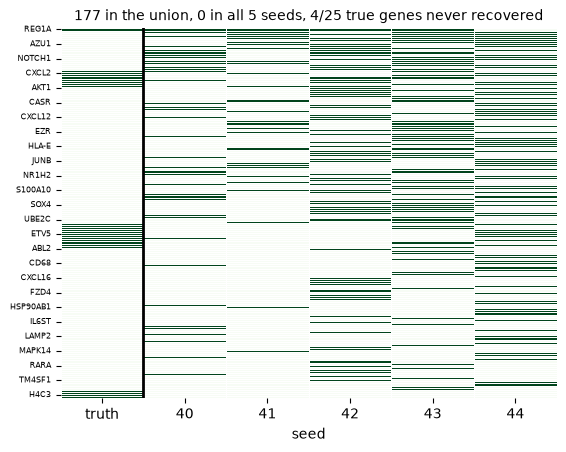

In [34]:
plot_membership(TRUE_LOCAL_GENES, df_local_list, labels=SEEDS, only_truth=False)

,truth,40,41,42,43,44
REG1A,True,True,True,True,True,False
BTG1,True,True,False,False,True,False
CXCL2,True,False,True,False,False,True
H2AZ1,True,False,False,False,True,True
MT1X,True,False,False,True,True,False
NEAT1,True,True,False,True,False,False
RARRES2,True,False,False,True,False,True
TPM2,True,False,False,False,True,True
TUBB,True,False,True,True,False,False
APP,True,False,False,False,False,True


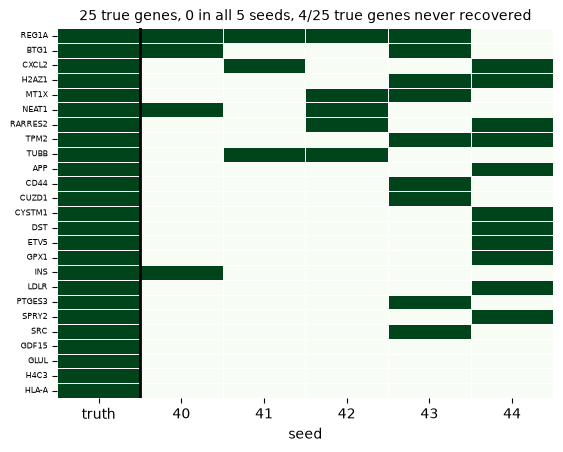

In [35]:
plot_membership(TRUE_LOCAL_GENES, df_local_list, labels=SEEDS, only_truth=True)

,truth,40,41,42,43,44
FZD4,False,False,True,True,True,False
H4C3,False,False,True,False,True,True
NEAT1,False,True,True,False,False,True
PRSS2,False,True,True,True,False,False
SOX4,False,False,True,False,True,True
...,...,...,...,...,...,...
IL12RB1,True,False,False,False,False,False
MEG3,True,False,False,False,False,False
NDRG1,True,False,False,False,False,False
SPP1,True,False,False,False,False,False


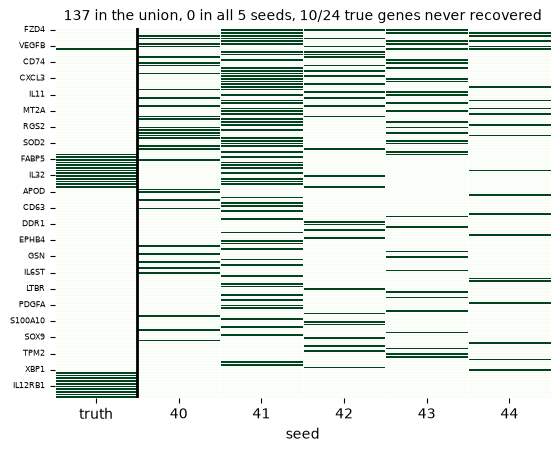

In [36]:
plot_membership(TRUE_GLOBAL_GENES, df_global_list, labels=SEEDS, only_truth=False)

,truth,40,41,42,43,44
TNFRSF12A,True,False,False,False,True,True
BTG1,True,False,False,False,True,False
C1QC,True,False,True,False,False,False
FABP5,True,True,False,False,False,False
GDF15,True,False,True,False,False,False
GPX3,True,False,True,False,False,False
HLA-A,True,False,True,False,False,False
HSP90AB1,True,False,False,False,False,True
IGFBP7,True,False,True,False,False,False
IL32,True,False,False,True,False,False


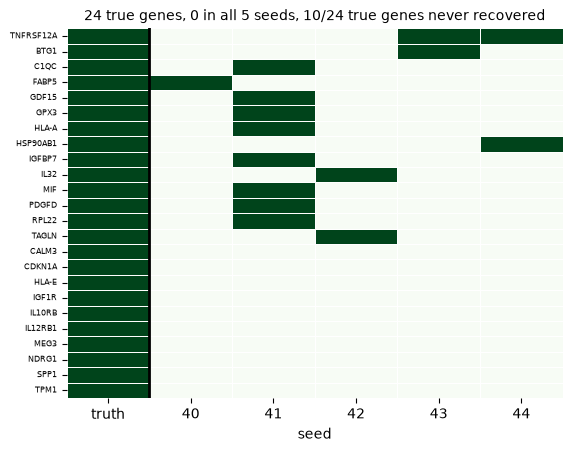

In [37]:
plot_membership(TRUE_GLOBAL_GENES, df_global_list, labels=SEEDS, only_truth=True)

## Cross-seed stability of the gene sets

Read the observed intersection against its own random expectation, never against zero:
`expected_intersection` is the overlap a random selection of the same set sizes from the same
pool already produces.

In [27]:
exp_intersection = {}
for df_list, component in [(df_local_list, 'local'), (df_global_list, 'global')]:
    sizes = [len(df.index) for df in df_list]
    exp_intersection[component] = {
        "sizes": sizes,
        "observed_all_seeds": len(overlap_matrix(df_list, labels=SEEDS)[1]),
        "expected_all_seeds": expected_intersection(sizes, pool=POOL),
    }
pd.DataFrame(exp_intersection).T

,sizes,observed_all_seeds,expected_all_seeds
local,"[23, 20, 19, 22, 20]",0,0.001734
global,"[20, 20, 17, 17, 10]",0,0.000521


,group,k,n_subsets,obs_mean,obs_sd,obs_min,obs_max,exp_mean,fold_mean
0,local,2,10,3.0,1.885618,0.0,7.0,1.991244,1.506596
1,local,3,10,0.5,0.707107,0.0,2.0,0.190393,2.626152
2,local,4,5,0.0,0.000000,0.0,0.0,0.018182,0.000000
3,local,5,1,0.0,0.000000,0.0,0.0,0.001734,0.000000
0,global,2,10,2.8,2.299758,0.0,6.0,1.285253,2.178559
1,global,3,10,0.7,1.059350,0.0,3.0,0.096944,7.220657
2,global,4,5,0.2,0.447214,0.0,1.0,0.007187,27.827650
3,global,5,1,0.0,0.000000,0.0,0.0,0.000521,0.000000


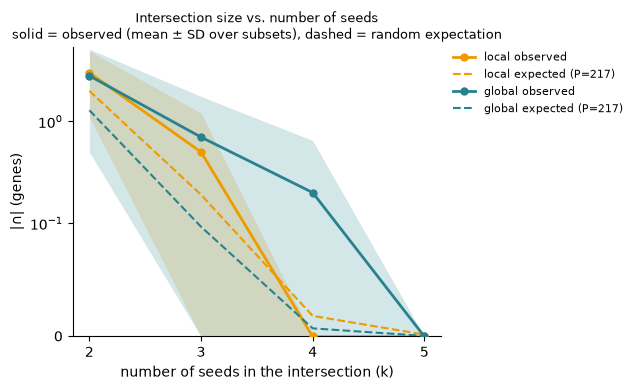

In [28]:
plot_intersection_by_k({"local": df_local_list, "global": df_global_list},
                       pool=POOL, log=True)

,group,k,n_subsets,p_mean,p_median,p_sd,p_min,p_max,obs_mean,exp_mean,fold_mean,method,n_iter
0,local,2,10,0.410800,0.395719,0.333411,0.001869,1.0,3.0,1.991244,1.511235,hypergeometric,0
1,local,3,10,0.655322,1.000000,0.447639,0.013199,1.0,0.5,0.190393,2.610613,monte-carlo,20000
2,local,4,5,1.000000,1.000000,0.000000,1.000000,1.0,0.0,0.018182,0.000000,monte-carlo,20000
3,local,5,1,1.000000,1.000000,0.000000,1.000000,1.0,0.0,0.001734,0.000000,monte-carlo,20000
0,global,2,10,0.388998,0.164179,0.445197,0.000679,1.0,2.8,1.285253,1.905696,hypergeometric,0
1,global,3,10,0.627999,1.000000,0.482308,0.000150,1.0,0.7,0.096944,5.458413,monte-carlo,20000
2,global,4,5,0.802430,1.000000,0.441780,0.012149,1.0,0.2,0.007187,17.678742,monte-carlo,20000
3,global,5,1,1.000000,1.000000,0.000000,1.000000,1.0,0.0,0.000521,0.000000,monte-carlo,20000


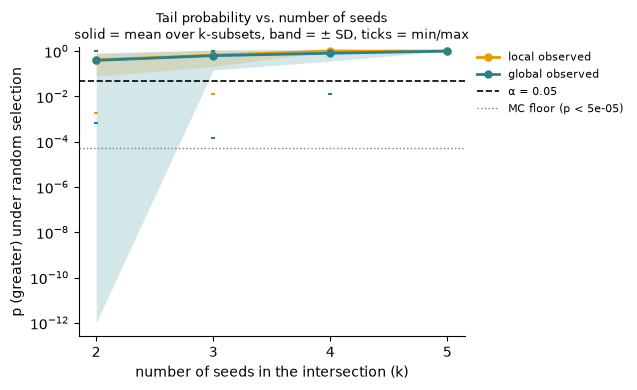

In [29]:
plot_tail_prob_by_k({"local": df_local_list, "global": df_global_list}, pool=POOL)

In [30]:
for name, df_list in [("local", df_local_list), ("global", df_global_list)]:
    overlap, common = overlap_matrix(df_list, labels=SEEDS)
    print(f"--- {name} ---")
    print(overlap)
    print(f"{len(common)} genes in all {len(df_list)} seeds:", sorted(common), "\n")

--- local ---
    40  41  42  43  44
40  23   7   0   2   2
41   7  20   3   4   4
42   0   3  19   2   2
43   2   4   2  22   4
44   2   4   2   4  20
0 genes in all 5 seeds: [] 

--- global ---
    40  41  42  43  44
40  20   4   4   5   0
41   4  20   2   5   2
42   4   2  17   6   0
43   5   5   6  17   0
44   0   2   0   0  10
0 genes in all 5 seeds: [] 

